# LM26 Lab — Time Series II: Volatility Models

Companion notebook to **From Calculus to Kelly, LM26**. It rebuilds the module's exhibits and computational examples from the closes of the TAIEX total-return index and the per-day realized variances of the 5-second TAIEX. It also computes the widget's starting values, solves the computational practice problems, and ends with an extension exercise.

| Part | Rebuilds |
|:--|:--|
| 1 | Data: TR23's log returns in percent, $T$, $A$; `vol4_rv.csv`, its sampling regimes and the daily target $V_t$ |
| 2 | The ARCH test by hand and with `het_arch` (Example 1), its permutation reference (experiment 3) and the knowledge check's ARCH(1) forecasts |
| 3 | EWMA by hand (Example 2), its weights, and $\lambda$ in hindsight (Example 3) |
| 4 | GARCH: the likelihood by hand, arch's normal and $t$ fits with classical and robust errors (Example 5, Exhibit 3), standardized residuals (Example 6), Deep Dive 2, the term structure (Example 4, the widget) and Exhibit 2 |
| 5 | What GARCH explains (Example 7) with experiments 1 and 2 |
| 6 | Realized variance: Exhibit 4, Exhibit 5, Example 8's file values, Deep Dive 3, the opening return's share, $V_t$ against $r_t^2$ |
| 7 | Out of sample: the six forecasts, Exhibit 1, Exhibit 7, Example 10, Exhibit 8, Exhibit 9, the window check |
| 8 | Practice problems 10, 11 and 12 |
| 9 | Optional: the 2025 numbers printed "from the raw download" (needs the 2025 5-second files) |
| 10 | Extension: an asymmetric GARCH and the falls after falls |

**Environment.** From the repository root, `uv sync` installs the locked Python environment (`uv.lock`). Open this notebook with the `.venv` kernel, or run `uv run --with jupyterlab jupyter lab`.

**Data.** The notebook reads FinMind files that you download once with your own token. From the repository root, run `uv run python data/fetch_finmind.py`, then `uv run python data/make_lab_data.py`. FinMind's licence does not allow the book to redistribute the data. After that, the notebook runs offline. The realized variances come with the repository (`data/derived/vol4_rv.csv`). Rebuilding them needs the 5-second TAIEX download, `uv run python data/fetch_intraday.py --series taiex5s` (5,351 requests, about nine hours on a free registered FinMind account at 600 calls an hour, re-run after each hourly stop).

`data/` then holds two files, and the notebook reads nothing outside `data/`:

- `taiex_tr.csv`: `date` and `price`, the daily closes of the TAIEX total-return index (FinMind `TaiwanStockTotalReturnIndex`, data_id TAIEX), 2 January 2003 to 8 October 2026.
- `vol4_rv.csv`: one row per session from 3 January 2005. It holds the sampling interval `regime_s` and the realized variances `rv_<h>` of the window 09:30:00–13:30:00 at nine intervals, with their return counts `n_<h>`. Its column `o2` is the squared log change from the previous close to 09:30:00. The file is derived from FinMind `TaiwanVariousIndicators5Seconds` and `TaiwanStockPrice`, with TWSE the original source.

**Conventions (as in the module).**

- TR23: $T=5{,}849$ log returns $r_t=\ln(1+R_t)$ from 3 January 2003, used in percent ($y_t=100r_t$) by every model, so variances are in %² a day.
- Years are calendar days / 365.25 and $A=T/\text{years}=246.12$; an annualized volatility is $\sqrt{A\times\text{variance}}$. Moments divide by $T$.
- The target is $V_t=10^4(\texttt{o2}+\texttt{rv\_15m})$ in %².
- GARCH(1,1) is arch's `arch_model(y, mean="Constant", vol="GARCH", p=1, q=1)`, started from arch's backcast. EWMA has $\lambda=0.94$, mean zero, and starts at the mean of $y_t^2$ over the first 246 returns.
- Out of sample: a window of $\operatorname{round}(5A)=1{,}231$ returns, both GARCH models refitted at each month's first session, forecasts from 2 January 2008.
- Newey–West: Bartlett weights, $\lfloor4(n/100)^{2/9}\rfloor$ lags, no small-sample correction; Mincer–Zarnowitz: HC0.
- Quantiles and medians use `method="inverted_cdf"`; counts against a threshold use the guard `1e-12`. Simulations create `np.random.default_rng([e, 20261011])` once per experiment $e$.

In [1]:
import datetime as dt
import math
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import statsmodels.api as sm
from arch import arch_model
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

DATA = Path("data")
EPS = 1e-12
SEED = 20261011
LAM = 0.94
pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_cols(12)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})


def show(label, value, fmt, printed):
    # print a value next to the module's printed value and assert that they agree
    got = format(value, fmt)
    print(f"{label}: {got}   [book: {printed}]")
    assert got == printed, (label, got, printed)


def nw_lags(n):
    # the book's lag rule (LM23)
    return math.floor(4 * (n / 100) ** (2 / 9))


def nw_se(d, lags):
    # Newey-West standard error of a mean: Bartlett weights, divisor n, no small-sample correction
    c = d - d.mean()
    n = len(c)
    s = float(c @ c) / n
    for k in range(1, lags + 1):
        s += 2 * (1 - k / (lags + 1)) * float(c[k:] @ c[:-k]) / n
    return math.sqrt(s / n)

## Part 1 — Data

Simple returns between consecutive closes, then log returns in percent. arch warns when the residual variance lies outside $[0.1,\ 10{,}000)$; daily variances in decimals (about 0.000147) are far below that range, in %² (about 1.47) inside it.

In [2]:
raw = pl.read_csv(DATA / "taiex_tr.csv").sort("date")
dates_all = raw["date"].to_list()
price = raw["price"].to_numpy()
R = price[1:] / price[:-1] - 1
dates = dates_all[1:]
T = len(R)
r = np.log1p(R)
y = 100 * r                                   # log returns in percent
years = (dt.date.fromisoformat(dates_all[-1]) - dt.date.fromisoformat(dates_all[0])).days / 365.25
A = T / years
pos = {d: i for i, d in enumerate(dates)}
print(f"{len(price)} closes {dates_all[0]} .. {dates_all[-1]}; returns {dates[0]} .. {dates[-1]}")
show("T", T, ",", "5,849")
show("A", A, ".2f", "246.12")
show("daily variance of r, decimals", float(np.var(r)), ".6f", "0.000147")
show("daily variance of r, %^2", float(np.var(y)), ".2f", "1.47")

i7, i2, i8 = pos["2025-04-07"], pos["2025-04-02"], pos["2025-04-08"]
show("7 April 2025, simple return (%)", 100 * R[i7], ".2f", "-9.70")
show("7 April 2025, log return (%)", y[i7], ".4f", "-10.2029")
assert int(np.argmin(R)) == i7               # TR23's largest fall


def ann(v):
    # annualized volatility in percent from a daily variance in %^2
    return math.sqrt(A * v)

5850 closes 2003-01-02 .. 2026-10-08; returns 2003-01-03 .. 2026-10-08
T: 5,849   [book: 5,849]
A: 246.12   [book: 246.12]
daily variance of r, decimals: 0.000147   [book: 0.000147]
daily variance of r, %^2: 1.47   [book: 1.47]
7 April 2025, simple return (%): -9.70   [book: -9.70]
7 April 2025, log return (%): -10.2029   [book: -10.2029]


The per-day realized variances. The file's first line is a comment (the credit to FinMind and TWSE), hence `comment_prefix="#"`. A missing grid prints `NaN`: the 10-second regime has no 15-second grid, and the 1-minute regime nothing finer.

In [3]:
rv = pl.read_csv(DATA / "vol4_rv.csv", comment_prefix="#").sort("date")
rv_dates = rv["date"].to_list()
assert rv_dates == [d for d in dates if d >= "2005-01-03"]      # TR23's sessions from 3 January 2005
show("T5S sessions", len(rv_dates), ",", "5,351")
print(rv.group_by("regime_s", maintain_order=True).agg(
    pl.len().alias("days"), pl.col("date").first().alias("first"), pl.col("date").last().alias("last")))

IV = [("5s", 5), ("10s", 10), ("15s", 15), ("30s", 30), ("1m", 60), ("5m", 300), ("10m", 600), ("15m", 900),
      ("30m", 1800)]
RV = {k: rv[f"rv_{k}"].to_numpy() for k, _ in IV}
NN = {k: rv[f"n_{k}"].to_numpy() for k, _ in IV}
O2 = rv["o2"].to_numpy()
reg = rv["regime_s"].to_numpy()
ryear = np.array([d[:4] for d in rv_dates])
for k, h in IV:
    ok = ~np.isnan(NN[k])
    assert np.all(NN[k][ok] == 14400 // h)
show("returns a day at 5 s", 14400 // 5, ",", "2,880")
show("returns a day at 15 min", 14400 // 900, "d", "16")

Vt = {k: 1e4 * (O2 + RV[k]) for k in ("5m", "15m", "30m")}       # the target V_t, %^2
i05 = pos["2005-01-03"]
V15 = np.full(T, np.nan)
V15[i05:] = Vt["15m"]                                              # on TR23's dates, NaN before 2005
show("7 April 2025: sqrt(V_t) (%)", math.sqrt(V15[i7]), ".4f", "10.0859")
show("7 April 2025: share of V_t before 09:30 (%)", 100 * 1e4 * O2[rv_dates.index("2025-04-07")] / V15[i7], ".2f", "99.99")
show("8 April 2025: sqrt(V_t) (%)", math.sqrt(V15[i8]), ".4f", "3.3873")

T5S sessions: 5,351   [book: 5,351]
shape: (4, 4)
┌──────────┬──────┬────────────┬────────────┐
│ regime_s ┆ days ┆ first      ┆ last       │
│ ---      ┆ ---  ┆ ---        ┆ ---        │
│ i64      ┆ u32  ┆ str        ┆ str        │
╞══════════╪══════╪════════════╪════════════╡
│ 60       ┆ 1503 ┆ 2005-01-03 ┆ 2011-01-14 │
│ 15       ┆ 764  ┆ 2011-01-17 ┆ 2014-02-21 │
│ 10       ┆ 214  ┆ 2014-02-24 ┆ 2014-12-27 │
│ 5        ┆ 2870 ┆ 2014-12-29 ┆ 2026-10-08 │
└──────────┴──────┴────────────┴────────────┘
returns a day at 5 s: 2,880   [book: 2,880]
returns a day at 15 min: 16   [book: 16]
7 April 2025: sqrt(V_t) (%): 10.0859   [book: 10.0859]
7 April 2025: share of V_t before 09:30 (%): 99.99   [book: 99.99]
8 April 2025: sqrt(V_t) (%): 3.3873   [book: 3.3873]


## Part 2 — The ARCH test (Example 1)

First the evidence of Section 2, by LM19's (19.5) (full-sample mean, divisor $T$): next-day log returns barely correlate, their sizes do. Then the test: regress $\hat\varepsilon_t^2$ on a constant and $K$ lags by OLS; the statistic is $T-K$ times R-squared, compared with the upper tail of $\chi^2_K$. statsmodels' `het_arch` squares the residuals it is given, so pass $y_t-\bar y$.

In [4]:
def rho(x, k):
    # LM19's (19.5): full-sample mean, divisor T in numerator and denominator
    xc = x - x.mean()
    return float(xc[k:] @ xc[:-k]) / float(xc @ xc)


show("rho_1 of r (LM19)", rho(r, 1), ".4f", "0.0393")
show("rho_1 of |r| (LM19)", rho(np.abs(r), 1), ".3f", "0.161")


def arch_test(x, K):
    z = x[K:] ** 2
    X = np.column_stack([np.ones(len(x) - K)] + [x[K - j - 1 : len(x) - j - 1] ** 2 for j in range(K)])
    b, *_ = np.linalg.lstsq(X, z, rcond=None)
    e = z - X @ b
    r2 = 1 - float(e @ e) / float((z - z.mean()) @ (z - z.mean()))
    lm = (len(x) - K) * r2
    check = het_arch(x, nlags=K, result_object=True)
    assert abs(check.lm - lm) < 1e-6 * lm
    return b, r2, lm, float(stats.chi2.sf(lm, K))


yc = y - y.mean()
b1, r21, lm1, p1 = arch_test(yc, 1)
show("K=1: a", b1[0], ".4f", "1.1779")
show("K=1: b_1", b1[1], ".3f", "0.196")
show("K=1: R-squared", r21, ".5f", "0.03844")
show("K=1: (T - 1) R-squared", lm1, ".1f", "224.8")
show("K=1: p-value", p1, ".1e", "8.2e-51")
b5, r25, lm5, p5 = arch_test(yc, 5)
show("K=5: statistic", lm5, ".1f", "696.3")
show("chi2_5, 5% point", float(stats.chi2.ppf(0.95, 5)), ".2f", "11.07")
print(f"K=5: p-value {p5:.3e} (below 1e-100: {p5 < 1e-100})")
show("K=5: sum of the slopes", float(b5[1:].sum()), ".3f", "0.529")
for x, v_, s_ in ((3.0, "2.94", "1.72"), (0.5, "1.23", "1.11")):
    show(f"knowledge check: variance after a {x}% surprise", 1.1779 + 0.1960 * x**2, ".2f", v_)
    show(f"knowledge check: its root", math.sqrt(1.1779 + 0.1960 * x**2), ".2f", s_)

rho_1 of r (LM19): 0.0393   [book: 0.0393]
rho_1 of |r| (LM19): 0.161   [book: 0.161]
K=1: a: 1.1779   [book: 1.1779]
K=1: b_1: 0.196   [book: 0.196]
K=1: R-squared: 0.03844   [book: 0.03844]
K=1: (T - 1) R-squared: 224.8   [book: 224.8]
K=1: p-value: 8.2e-51   [book: 8.2e-51]
K=5: statistic: 696.3   [book: 696.3]
chi2_5, 5% point: 11.07   [book: 11.07]
K=5: p-value 3.055e-148 (below 1e-100: True)
K=5: sum of the slopes: 0.529   [book: 0.529]
knowledge check: variance after a 3.0% surprise: 2.94   [book: 2.94]
knowledge check: its root: 1.72   [book: 1.72]
knowledge check: variance after a 0.5% surprise: 1.23   [book: 1.23]
knowledge check: its root: 1.11   [book: 1.11]


These $\chi^2$ p-values are nominal: (26.1) needs a finite fourth moment, which LM15's fit ($\nu=3.065$) lacks (LM19).

Experiment 3 needs no moment. It shuffles TR23's days 20,000 times with one generator, `np.random.default_rng([3, 20261011])`, as LM21's experiment 8 shuffled dates, and computes both statistics on each shuffle. A shuffle keeps every return but breaks any dependence between days, so the shuffles show how large the statistics get without clustering.

The largest statistics depend on the seed, so the module prints only that no shuffle reaches 224.8 or 696.3; the cell prints this run's largest. It takes about ten seconds.

In [5]:
def arch_lm(x, K):
    # the statistic (T - K) R-squared alone, for the shuffles (arch_test above also calls het_arch)
    z = x[K:] ** 2
    X = np.column_stack([np.ones(len(x) - K)] + [x[K - j - 1 : len(x) - j - 1] ** 2 for j in range(K)])
    b, *_ = np.linalg.lstsq(X, z, rcond=None)
    e = z - X @ b
    return (len(x) - K) * (1 - float(e @ e) / float((z - z.mean()) @ (z - z.mean())))


NPERM = 20_000
rng3 = np.random.default_rng([3, SEED])
perm1, perm5 = np.empty(NPERM), np.empty(NPERM)
t0 = time.time()
for i in range(NPERM):
    xs = yc[rng3.permutation(T)]          # the mean is unchanged, so xs is the shuffled series' own residual
    perm1[i], perm5[i] = arch_lm(xs, 1), arch_lm(xs, 5)
print(f"{NPERM:,} shuffles in {time.time() - t0:.0f} s")
print(f"largest shuffled statistics in this run: {perm1.max():.1f} (K=1) and {perm5.max():.1f} (K=5)")
n1, n5 = int((perm1 >= lm1).sum()), int((perm5 >= lm5).sum())
print(f"shuffles at or above the observed 224.8 and 696.3: {n1} and {n5}   [book: no shuffle reaches them]")
assert n1 == 0 and n5 == 0
q1, q5 = (float(np.quantile(p, 0.99, method="inverted_cdf")) for p in (perm1, perm5))
print(f"99% points of the shuffles: {q1:.2f} (K=1) and {q5:.2f} (K=5); of chi2_1 and chi2_5: "
      f"{stats.chi2.ppf(0.99, 1):.2f} and {stats.chi2.ppf(0.99, 5):.2f}")

20,000 shuffles in 8 s
largest shuffled statistics in this run: 84.1 (K=1) and 88.0 (K=5)
shuffles at or above the observed 224.8 and 696.3: 0 and 0   [book: no shuffle reaches them]
99% points of the shuffles: 8.86 (K=1) and 23.83 (K=5); of chi2_1 and chi2_5: 6.63 and 15.09


## Part 3 — EWMA (Example 2, Example 3)

The recursion is $\sigma^2_{t+1\mid t}=\lambda\sigma^2_{t\mid t-1}+(1-\lambda)y_t^2$, started at the mean of $y_t^2$ over the first 246 returns. `ewma(lam)[t]` is the forecast for day $t$ made at the close of day $t-1$; its last entry is the forecast after 8 October 2026.

In [6]:
def ewma(lam):
    ew = np.empty(T + 1)
    ew[0] = float(np.mean(y[:246] ** 2))
    for t in range(T):
        ew[t + 1] = lam * ew[t] + (1 - lam) * y[t] ** 2
    return ew


ew = ewma(LAM)
show("start (%^2)", ew[0], ".2f", "1.84")
show("forecast for 7 April (%^2)", ew[i7], ".4f", "2.4351")
show("forecast for 7 April (%)", math.sqrt(ew[i7]), ".4f", "1.5605")
show("r^2 on 7 April (%^2)", y[i7] ** 2, ".4f", "104.0999")
show("0.94 x 2.4351", 0.94 * 2.4351, ".4f", "2.2890")
show("0.06 x 104.0999", 0.06 * 104.0999, ".4f", "6.2460")
show("forecast for 8 April (%)", math.sqrt(ew[i8]), ".4f", "2.9215")
show("forecast for 8 April from the printed parts", math.sqrt(2.2890 + 6.2460), ".4f", "2.9215")

w = (1 - LAM) * LAM ** np.arange(10_000)
print(f"weights sum to {w.sum():.10f}")
show("effective window 1/(1 - lam) (days)", 1 / (1 - LAM), ".1f", "16.7")
show("weights' half-life ln(1/2)/ln(lam) (days)", math.log(0.5) / math.log(LAM), ".1f", "11.2")
show("weight on the last 75 days (%)", 100 * (1 - LAM**75), ".1f", "99.0")
show("RiskMetrics' effective days at a 1% tolerance, ln(0.01)/ln(0.94)", math.log(0.01) / math.log(LAM), ".1f", "74.4")
print(f"weight on the last 74 days {100 * (1 - LAM**74):.2f}%, on the last 75 {100 * (1 - LAM**75):.2f}%")
assert 1 - LAM**75 >= 0.99 > 1 - LAM**74          # its Table 5.7 lists 74 days; 75 whole days reach 99%
show("knowledge check: effective window at 0.97", 1 / 0.03, ".1f", "33.3")
show("knowledge check: weights' half-life at 0.97", math.log(0.5) / math.log(0.97), ".2f", "22.76")

start (%^2): 1.84   [book: 1.84]
forecast for 7 April (%^2): 2.4351   [book: 2.4351]
forecast for 7 April (%): 1.5605   [book: 1.5605]
r^2 on 7 April (%^2): 104.0999   [book: 104.0999]
0.94 x 2.4351: 2.2890   [book: 2.2890]
0.06 x 104.0999: 6.2460   [book: 6.2460]
forecast for 8 April (%): 2.9215   [book: 2.9215]
forecast for 8 April from the printed parts: 2.9215   [book: 2.9215]
weights sum to 1.0000000000
effective window 1/(1 - lam) (days): 16.7   [book: 16.7]
weights' half-life ln(1/2)/ln(lam) (days): 11.2   [book: 11.2]
weight on the last 75 days (%): 99.0   [book: 99.0]
RiskMetrics' effective days at a 1% tolerance, ln(0.01)/ln(0.94): 74.4   [book: 74.4]
weight on the last 74 days 98.97%, on the last 75 99.03%
knowledge check: effective window at 0.97: 33.3   [book: 33.3]
knowledge check: weights' half-life at 0.97: 22.76   [book: 22.76]


The out-of-sample design of Section 7 fixes the test days. The window is $\operatorname{round}(5A)=1{,}231$ returns, and the first forecast day is the first month's first session with a full window behind it. Example 3 scores EWMA on those days for every $\lambda$ on a grid; choosing the best uses the test days, so it is in-sample.

window: 1,231   [book: 1,231]
first out-of-sample day 2008-01-02 | window 2003-01-16 .. 2007-12-31
out-of-sample days: 4,609   [book: 4,609]
first out-of-sample day's index t: 1,240   [book: 1,240]
the start's weight in that day's forecast, lam^t: 5e-34   [book: 5e-34]
QLIKE at 0.94: 0.5153   [book: 0.5153]
QLIKE at 0.97: 0.5436   [book: 0.5436]
best lambda: 0.905   [book: 0.905]
its QLIKE: 0.5087   [book: 0.5087]


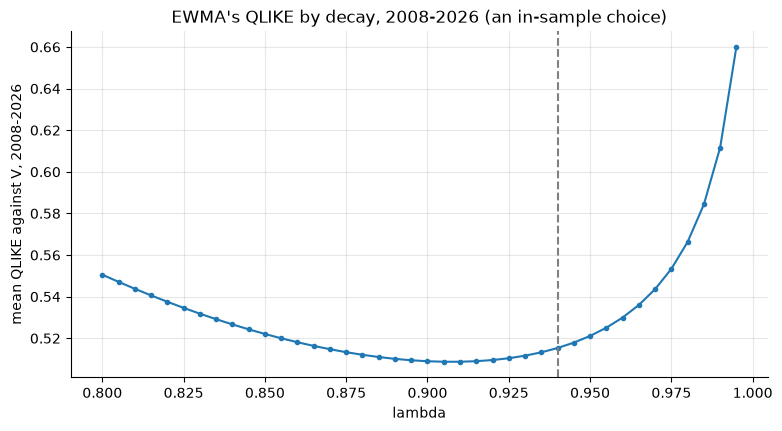

In [7]:
W = round(5 * A)
month = [d[:7] for d in dates]
starts = [i for i in range(T) if i == 0 or month[i] != month[i - 1]]
first = next(i for i in starts if i >= W)
oos = np.arange(first, T)
show("window", W, ",", "1,231")
print("first out-of-sample day", dates[first], "| window", dates[first - W], "..", dates[first - 1])
show("out-of-sample days", len(oos), ",", "4,609")
show("first out-of-sample day's index t", first, ",", "1,240")
show("the start's weight in that day's forecast, lam^t", LAM**first, ".0e", "5e-34")


def qlike(v, f):
    return v / f - np.log(v / f) - 1


hV = V15[oos]
lams = np.round(np.arange(0.800, 0.9951, 0.005), 3)
ql = np.array([float(qlike(hV, ewma(float(lam))[oos]).mean()) for lam in lams])
show("QLIKE at 0.94", ql[list(lams).index(0.94)], ".4f", "0.5153")
show("QLIKE at 0.97", ql[list(lams).index(0.97)], ".4f", "0.5436")
show("best lambda", lams[int(ql.argmin())], ".3f", "0.905")
show("its QLIKE", ql.min(), ".4f", "0.5087")
plt.plot(lams, ql, marker=".")
plt.axvline(0.94, ls="--", color="grey")
plt.xlabel("lambda")
plt.ylabel("mean QLIKE against V, 2008-2026")
plt.title("EWMA's QLIKE by decay, 2008-2026 (an in-sample choice)")
plt.show()

## Part 4 — GARCH(1,1) by maximum likelihood (Example 5, Exhibit 3)

arch starts the recursion from its backcast, the mean of the first 75 squared residuals about the sample mean with weights proportional to $0.94^j$: $\sigma_1^2=\omega+(\alpha+\beta)\times\text{backcast}$. The log-likelihood (26.5) by hand must equal arch's. `cov_type="classic"` inverts $-\ell''$; `"robust"` (arch's default) is the sandwich.

In [8]:
def fit(x, dist, cov="robust"):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        res = arch_model(x, mean="Constant", vol="GARCH", p=1, q=1, dist=dist).fit(disp="off", cov_type=cov)
    assert res.convergence_flag == 0
    return res


def backcast(e):
    wb = 0.94 ** np.arange(min(75, len(e)))
    return float(np.sum(e[: len(wb)] ** 2 * wb / wb.sum()))


def garch_filter(om, al, be, e, bc):
    # sigma^2 of each day of e, plus the forecast after the last one
    s2 = np.empty(len(e) + 1)
    s2[0] = om + (al + be) * bc
    for t in range(len(e)):
        s2[t + 1] = om + al * e[t] ** 2 + be * s2[t]
    return s2


t0 = time.perf_counter()
gn, gn_c = fit(y, "normal"), fit(y, "normal", "classic")
gt, gt_c = fit(y, "t"), fit(y, "t", "classic")
print(f"four fits in {time.perf_counter() - t0:.1f} s")
pn, pt = gn.params.to_numpy(), gt.params.to_numpy()        # arch returns pandas Series: g, omega, alpha, beta (, nu)
cvn = np.asarray(gn.conditional_volatility)
bc = backcast(y - y.mean())
s2 = garch_filter(pn[1], pn[2], pn[3], y - pn[0], bc)      # s2[t]: day t's variance; s2[T]: the next day's
ll = -0.5 * float(np.sum(np.log(2 * np.pi) + np.log(s2[:T]) + (y - pn[0]) ** 2 / s2[:T]))
show("backcast (%^2)", bc, ".2f", "2.78")
print(f"log-likelihood by hand {ll:.6f}, arch {gn.loglikelihood:.6f}, difference {ll - gn.loglikelihood:.1e}")
assert abs(ll - gn.loglikelihood) < 1e-6 and np.max(np.abs(s2[:T] - cvn**2)) < 1e-9
show("l, normal", gn.loglikelihood, ",.2f", "-8,647.25")

four fits in 0.1 s
backcast (%^2): 2.78   [book: 2.78]
log-likelihood by hand -8647.252087, arch -8647.252087, difference 0.0e+00
l, normal: -8,647.25   [book: -8,647.25]


In [9]:
pers, uvar = float(pn[2] + pn[3]), float(pn[1] / (1 - pn[2] - pn[3]))
pers_t, uvar_t = float(pt[2] + pt[3]), float(pt[1] / (1 - pt[2] - pt[3]))


def half_life(p):
    return math.log(0.5) / math.log(p)


names = ["g (% a day)", "omega (%^2)", "alpha", "beta", "nu"]
x3 = pl.DataFrame({
    "parameter": names,
    "normal": [*(f"{v:.4f}" for v in pn), "-"],
    "classical SE": [*(f"{v:.4f}" for v in gn_c.std_err.to_numpy()), ""],
    "robust SE": [*(f"{v:.4f}" for v in gn.std_err.to_numpy()), ""],
    "t": [*(f"{v:.4f}" for v in pt[:4]), f"{pt[4]:.2f}"],
    "classical SE (t)": [*(f"{v:.4f}" for v in gt_c.std_err.to_numpy()[:4]), f"{gt_c.std_err.to_numpy()[4]:.2f}"],
    "robust SE (t)": [*(f"{v:.4f}" for v in gt.std_err.to_numpy()[:4]), f"{gt.std_err.to_numpy()[4]:.2f}"],
})
print(x3)
book = {"normal": ["0.0809", "0.0249", "0.0913", "0.8932", "-"], "classical SE": ["0.0123", "0.0040", "0.0076", "0.0086", ""],
        "robust SE": ["0.0126", "0.0068", "0.0137", "0.0151", ""], "t": ["0.0965", "0.0149", "0.0663", "0.9247", "5.54"],
        "classical SE (t)": ["0.0114", "0.0036", "0.0081", "0.0090", "0.41"],
        "robust SE (t)": ["0.0114", "0.0043", "0.0104", "0.0117", "0.41"]}
for col, vals in book.items():
    assert x3[col].to_list() == vals, (col, x3[col].to_list())
print("the table agrees with Exhibit 3")
show("alpha + beta, normal", pers, ".5f", "0.98443")
show("unconditional variance (%^2)", uvar, ".3f", "1.597")
show("annualized", ann(uvar), ".2f", "19.83")
show("TR23's sqrt(A) s_r (LM19)", ann(float(np.var(y))), ".2f", "18.99")
show("half-life, normal (sessions)", half_life(pers), ".1f", "44.2")
show("alpha + beta, t", pers_t, ".5f", "0.99098")
show("unconditional variance, t", uvar_t, ".3f", "1.651")
show("annualized, t", ann(uvar_t), ".2f", "20.16")
show("half-life, t", half_life(pers_t), ".1f", "76.5")
show("l, t", gt.loglikelihood, ",.2f", "-8,463.90")
show("l gain of the t fit", gt.loglikelihood - gn.loglikelihood, ".2f", "183.35")
show("knowledge check: robust / classical SE of alpha", gn.std_err.to_numpy()[2] / gn_c.std_err.to_numpy()[2], ".2f", "1.80")

shape: (5, 7)
┌─────────────┬────────┬──────────────┬───────────┬────────┬──────────────────┬───────────────┐
│ parameter   ┆ normal ┆ classical SE ┆ robust SE ┆ t      ┆ classical SE (t) ┆ robust SE (t) │
│ ---         ┆ ---    ┆ ---          ┆ ---       ┆ ---    ┆ ---              ┆ ---           │
│ str         ┆ str    ┆ str          ┆ str       ┆ str    ┆ str              ┆ str           │
╞═════════════╪════════╪══════════════╪═══════════╪════════╪══════════════════╪═══════════════╡
│ g (% a day) ┆ 0.0809 ┆ 0.0123       ┆ 0.0126    ┆ 0.0965 ┆ 0.0114           ┆ 0.0114        │
│ omega (%^2) ┆ 0.0249 ┆ 0.0040       ┆ 0.0068    ┆ 0.0149 ┆ 0.0036           ┆ 0.0043        │
│ alpha       ┆ 0.0913 ┆ 0.0076       ┆ 0.0137    ┆ 0.0663 ┆ 0.0081           ┆ 0.0104        │
│ beta        ┆ 0.8932 ┆ 0.0086       ┆ 0.0151    ┆ 0.9247 ┆ 0.0090           ┆ 0.0117        │
│ nu          ┆ -      ┆              ┆           ┆ 5.54   ┆ 0.41             ┆ 0.41          │
└─────────────┴────────┴──

The half-life's uncertainty: the delta method (20.8) on $\ln\frac12/\ln(\alpha+\beta)$ with the robust covariance, against the robust interval for $\alpha+\beta$ mapped through the half-life. Near 1 the mapped interval is lopsided. The same delta method gives the unconditional volatility $\sqrt{A\,\omega/(1-\alpha-\beta)}$ its standard error.

In [10]:
cov_r = gn.param_cov.to_numpy()
var_p = cov_r[2, 2] + cov_r[3, 3] + 2 * cov_r[2, 3]
grad = -math.log(0.5) / (pers * math.log(pers) ** 2)
se_hl = math.sqrt(grad**2 * var_p)
z = float(stats.norm.ppf(0.975))
hl = half_life(pers)
show("delta-method SE of the half-life", se_hl, ".1f", "16.1")
show("delta interval, low", hl - z * se_hl, ".0f", "13")
show("delta interval, high", hl + z * se_hl, ".0f", "76")
show("robust SE of alpha + beta", math.sqrt(var_p), ".4f", "0.0056")
lo, hi = pers - z * math.sqrt(var_p), pers + z * math.sqrt(var_p)
show("interval for alpha + beta, low", lo, ".5f", "0.97342")
show("interval for alpha + beta, high", hi, ".5f", "0.99544")
show("mapped half-life, low", half_life(lo), ".0f", "26")
show("mapped half-life, high", half_life(hi), ".0f", "152")

cov_t = gt.param_cov.to_numpy()
se_pt = math.sqrt(cov_t[2, 2] + cov_t[3, 3] + 2 * cov_t[2, 3])
lo_t, hi_t = pers_t - z * se_pt, pers_t + z * se_pt
show("t fit: interval for alpha + beta, low", lo_t, ".5f", "0.98343")
show("t fit: interval for alpha + beta, high", hi_t, ".5f", "0.99853")
show("t fit: mapped half-life, low", half_life(lo_t), ".0f", "41")
show("t fit: mapped half-life, high", half_life(hi_t), ".0f", "471")


def uvol_se(p, cov):
    # delta method for sqrt(A omega / (1 - alpha - beta)), in percentage points a year
    om, ps = p[1], p[2] + p[3]
    g_ = np.zeros(len(p))
    g_[1] = 1 / (1 - ps)
    g_[2] = g_[3] = om / (1 - ps) ** 2
    return math.sqrt(A) / (2 * math.sqrt(om / (1 - ps))) * math.sqrt(float(g_ @ cov @ g_))


show("SE of the normal fit's unconditional volatility (points)", uvol_se(pn, cov_r), ".1f", "2.3")
show("SE of the t fit's unconditional volatility (points)", uvol_se(pt, cov_t), ".1f", "2.9")

delta-method SE of the half-life: 16.1   [book: 16.1]
delta interval, low: 13   [book: 13]
delta interval, high: 76   [book: 76]
robust SE of alpha + beta: 0.0056   [book: 0.0056]
interval for alpha + beta, low: 0.97342   [book: 0.97342]
interval for alpha + beta, high: 0.99544   [book: 0.99544]
mapped half-life, low: 26   [book: 26]
mapped half-life, high: 152   [book: 152]
t fit: interval for alpha + beta, low: 0.98343   [book: 0.98343]
t fit: interval for alpha + beta, high: 0.99853   [book: 0.99853]
t fit: mapped half-life, low: 41   [book: 41]
t fit: mapped half-life, high: 471   [book: 471]
SE of the normal fit's unconditional volatility (points): 2.3   [book: 2.3]
SE of the t fit's unconditional volatility (points): 2.9   [book: 2.9]


### Standardized residuals (Example 6) and Deep Dive 2

Moments divide by $T$ (SciPy's `skew` and `kurtosis` defaults). The Ljung–Box statistic (25.5) of $\lvert\hat\xi_t\rvert$ uses ten lags; LM25's 1,820 is the same statistic on $\lvert r_t\rvert$.

In [11]:
xin = (y - pn[0]) / cvn
show("excess kurtosis of xi", stats.kurtosis(xin), ".2f", "2.57")
show("skewness of xi", stats.skew(xin), ".2f", "-0.59")
show("excess kurtosis of r (LM17's 5.428)", stats.kurtosis(y), ".3f", "5.428")
show("skewness of r", stats.skew(y), ".2f", "-0.47")
lb_xi = acorr_ljungbox(np.abs(xin), lags=[10]).to_numpy()[0]
lb_r = acorr_ljungbox(np.abs(y), lags=[10]).to_numpy()[0]
show("Q_LB(10) of |xi|", lb_xi[0], ".1f", "27.6")
show("its p-value", lb_xi[1], ".3f", "0.002")
show("Q_LB(10) of |r| (LM25)", lb_r[0], ",.0f", "1,820")
_, _, lmx, px = arch_test(xin - xin.mean(), 5)
show("ARCH test (K=5) on xi", lmx, ".1f", "14.3")
show("its p-value", px, ".3f", "0.014")

z5 = -4.107                                   # LM5's lab threshold
show("days at or below -4.107, standardized by s", int(((y - y.mean()) / y.std() <= z5 + EPS).sum()), "d", "17")
show("days at or below -4.107, standardized by GARCH", int((xin <= z5 + EPS).sum()), "d", "9")
show("expected under the normal model", T * stats.norm.cdf(z5), ".3f", "0.117")

den = 1 - pers**2 - 2 * pn[2] ** 2
show("Deep Dive 2: denominator", den, ".6f", "0.014239")
show("Deep Dive 2: kurtosis of the normal GARCH", 3 * (1 - pers**2) / den, ".2f", "6.51")
k_xi = 3 + 6 / (pt[4] - 4)                    # (15.10) at the t fit's nu
show("Deep Dive 2: E xi^4 of the t fit", k_xi, ".2f", "6.89")
show("Deep Dive 2: (a+b)^2 + (E xi^4 - 1) a^2, t fit", pers_t**2 + (k_xi - 1) * pt[2] ** 2, ".3f", "1.008")

excess kurtosis of xi: 2.57   [book: 2.57]
skewness of xi: -0.59   [book: -0.59]
excess kurtosis of r (LM17's 5.428): 5.428   [book: 5.428]
skewness of r: -0.47   [book: -0.47]
Q_LB(10) of |xi|: 27.6   [book: 27.6]
its p-value: 0.002   [book: 0.002]
Q_LB(10) of |r| (LM25): 1,820   [book: 1,820]
ARCH test (K=5) on xi: 14.3   [book: 14.3]
its p-value: 0.014   [book: 0.014]
days at or below -4.107, standardized by s: 17   [book: 17]
days at or below -4.107, standardized by GARCH: 9   [book: 9]
expected under the normal model: 0.117   [book: 0.117]
Deep Dive 2: denominator: 0.014239   [book: 0.014239]
Deep Dive 2: kurtosis of the normal GARCH: 6.51   [book: 6.51]
Deep Dive 2: E xi^4 of the t fit: 6.89   [book: 6.89]
Deep Dive 2: (a+b)^2 + (E xi^4 - 1) a^2, t fit: 1.008   [book: 1.008]


### The term structure of the forecast (Example 4 and the widget)

By (26.4), $\sigma^2_{t+m\mid t}=\sigma^2+(\alpha+\beta)^{m-1}(\sigma^2_{t+1\mid t}-\sigma^2)$, from the full-sample normal fit. arch's `forecast` must give the same path.

largest difference from arch's forecast: 1.9e-14
sigma_t on 7 April (%): 1.737   [book: 1.737]
sigma_t+1|t (%): 3.517   [book: 3.517]
sigma^2_t+1|t (%^2): 12.3695   [book: 12.3695]
sigma_t+5|t (%): 3.42   [book: 3.42]
sigma_t+20|t (%): 3.10   [book: 3.10]
sigma_t+44|t (%): 2.66   [book: 2.66]
sigma_t+250|t (%): 1.35   [book: 1.35]
unconditional sigma (% a day): 1.264   [book: 1.264]
widget: tomorrow, a year: 55.18   [book: 55.18]
widget: average over 20 days, a year: 51.83   [book: 51.83]
widget: average over 250 days, a year: 32.57   [book: 32.57]
forecast after 8 October 2026 (%): 1.092   [book: 1.092]
its annualized value: 17.13   [book: 17.13]


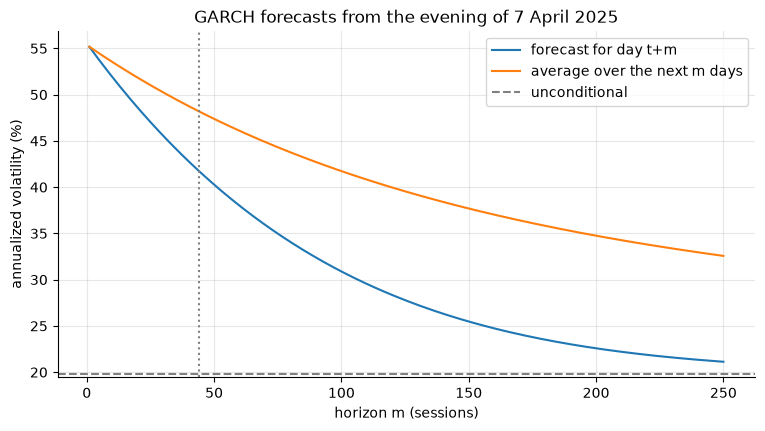

In [12]:
def term(s2next, m_max=250):
    mm = np.arange(1, m_max + 1)
    return uvar + pers ** (mm - 1) * (s2next - uvar)


s2_7 = float(s2[i7 + 1])                      # the forecast for 8 April, made on the evening of 7 April
p7 = term(s2_7)
fc = gn.forecast(horizon=250, start=i7, reindex=False).variance.to_numpy()[0]
print(f"largest difference from arch's forecast: {np.max(np.abs(p7 - fc)):.1e}")
assert np.max(np.abs(p7 - fc)) < 1e-12
show("sigma_t on 7 April (%)", float(cvn[i7]), ".3f", "1.737")
show("sigma_t+1|t (%)", math.sqrt(s2_7), ".3f", "3.517")
show("sigma^2_t+1|t (%^2)", s2_7, ".4f", "12.3695")
for m, v_ in ((5, "3.42"), (20, "3.10"), (44, "2.66"), (250, "1.35")):
    show(f"sigma_t+{m}|t (%)", math.sqrt(p7[m - 1]), ".2f", v_)
show("unconditional sigma (% a day)", math.sqrt(uvar), ".3f", "1.264")
show("widget: tomorrow, a year", ann(p7[0]), ".2f", "55.18")
show("widget: average over 20 days, a year", ann(float(p7[:20].mean())), ".2f", "51.83")
show("widget: average over 250 days, a year", ann(float(p7.mean())), ".2f", "32.57")
s2_T = float(s2[T])
show("forecast after 8 October 2026 (%)", math.sqrt(s2_T), ".3f", "1.092")
show("its annualized value", ann(s2_T), ".2f", "17.13")

mm = np.arange(1, 251)
plt.plot(mm, [ann(v) for v in p7], label="forecast for day t+m")
plt.plot(mm, [ann(float(p7[:m].mean())) for m in mm], label="average over the next m days")
plt.axhline(ann(uvar), ls="--", color="grey", label="unconditional")
plt.axvline(half_life(pers), ls=":", color="grey")
plt.xlabel("horizon m (sessions)")
plt.ylabel("annualized volatility (%)")
plt.title("GARCH forecasts from the evening of 7 April 2025")
plt.legend()
plt.show()

### Exhibit 2: volatility by week

At each ISO week's last session: GARCH's in-sample $\sqrt A\,\sigma_t$, EWMA's $\sqrt{A\sigma^2_{t\mid t-1}}$, and the realized $\sqrt{A\times\text{the week's mean }V_t}$ from 2005. Weekly points only: the book publishes no daily series.

weeks: 1,224   [book: 1,224]
realized weeks: 1,120   [book: 1,120]
GARCH maximum (% a year): 70.41   [book: 70.41]
EWMA maximum (% a year): 60.11   [book: 60.11]
realized maximum (% a year): 100.16   [book: 100.16]
all three on 2025-04-11 2025-04-11 2025-04-11


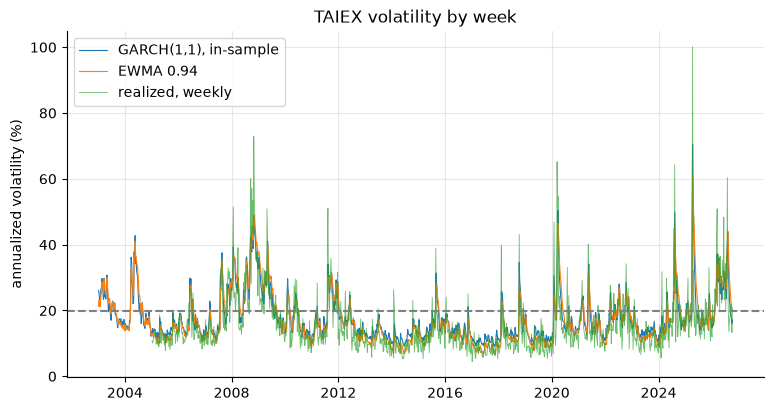

In [13]:
weeks = {}
for i, d in enumerate(dates):
    weeks.setdefault(dt.date.fromisoformat(d).isocalendar()[:2], []).append(i)
ends = [ids[-1] for ids in weeks.values()]
real_w = [(ids[-1], ann(float(np.mean(V15[ids])))) for ids in weeks.values() if dates[ids[0]] >= "2005-01-03"]
show("weeks", len(ends), ",", "1,224")
show("realized weeks", len(real_w), ",", "1,120")
ig, ie = int(np.argmax(cvn)), int(np.argmax(ew[:T]))
jr = int(np.argmax([v for _, v in real_w]))
show("GARCH maximum (% a year)", ann(float(cvn[ig] ** 2)), ".2f", "70.41")
show("EWMA maximum (% a year)", ann(float(ew[ie])), ".2f", "60.11")
show("realized maximum (% a year)", real_w[jr][1], ".2f", "100.16")
print("all three on", dates[ig], dates[ie], dates[real_w[jr][0]])
assert dates[ig] == dates[ie] == dates[real_w[jr][0]] == "2025-04-11" and ig in ends

xd = [dt.date.fromisoformat(dates[i]) for i in ends]
plt.plot(xd, [ann(float(cvn[i] ** 2)) for i in ends], lw=0.8, label="GARCH(1,1), in-sample")
plt.plot(xd, [ann(float(ew[i])) for i in ends], lw=0.8, label="EWMA 0.94")
plt.plot([dt.date.fromisoformat(dates[i]) for i, _ in real_w], [v for _, v in real_w], lw=0.6, alpha=0.7,
         label="realized, weekly")
plt.axhline(ann(uvar), ls="--", color="grey")
plt.ylabel("annualized volatility (%)")
plt.title("TAIEX volatility by week")
plt.legend()
plt.show()

## Part 5 — What GARCH explains (Example 7)

Falls of 3% or more (`R <= -0.03 + 1e-12`) and rises above 3%; GARCH's expected number of next-day falls uses the residuals' own distribution: the share of $\hat\xi$ at or below $(100\ln0.97-\hat g)/\sigma_{t+1\mid t}$.

In [14]:
fall = R <= -0.03 + EPS
rise = R > 0.03 + EPS
idf, idr = np.flatnonzero(fall[:-1]), np.flatnonzero(rise[:-1])
snext = np.sqrt(s2[1 : T + 1])                 # sigma_{t+1|t} for t = 0 .. T-1
F_emp = np.searchsorted(np.sort(xin), (100 * math.log(0.97) - pn[0]) / snext, side="right") / T
show("falls of 3% or more", len(idf), "d", "108")
show("followed by a fall", int(fall[idf + 1].sum()), "d", "13")
show("GARCH expects", float(F_emp[idf].sum()), ".1f", "7.8")
show("independent days would give", 108 * 108 / 5848, ".1f", "2.0")
show("rises above 3%", len(idr), "d", "67")
show("followed by a fall", int(fall[idr + 1].sum()), "d", "3")
show("GARCH expects", float(F_emp[idr].sum()), ".1f", "5.4")

big = np.abs(R[:-1]) >= 0.02 - EPS
nxt = np.abs(R[1:])
pred = float(np.mean(np.abs(xin))) * snext[:-1] / 100
show("days with |R| >= 2%", int(big.sum()), "d", "489")
show("next-day mean |R| after them (%)", 100 * float(nxt[big].mean()), ".2f", "1.27")
show("after the other days (%)", 100 * float(nxt[~big].mean()), ".2f", "0.80")
show("GARCH's prediction after them (%)", 100 * float(pred[big].mean()), ".2f", "1.35")
show("after the other days (%)", 100 * float(pred[~big].mean()), ".2f", "0.79")

falls of 3% or more: 108   [book: 108]
followed by a fall: 13   [book: 13]
GARCH expects: 7.8   [book: 7.8]
independent days would give: 2.0   [book: 2.0]
rises above 3%: 67   [book: 67]
followed by a fall: 3   [book: 3]
GARCH expects: 5.4   [book: 5.4]
days with |R| >= 2%: 489   [book: 489]
next-day mean |R| after them (%): 1.27   [book: 1.27]
after the other days (%): 0.80   [book: 0.80]
GARCH's prediction after them (%): 1.35   [book: 1.35]
after the other days (%): 0.79   [book: 0.79]


Experiments 1 and 2: 1,000 paths of 5,849 days from each fit, with normal $\xi_t$ in experiment 1 and Student $t$ in experiment 2, $\sigma_t^2$ started at the unconditional variance. Each day draws one vector of 1,000 innovations (element $k$ for path $k$); a $t$ draw is scaled by $\sqrt{(\nu-2)/\nu}$ to variance 1. Medians carry LM18's batch standard error (20 batches of 50 paths, divisor 20). Each experiment takes about a second.

In [15]:
mi = np.unique(np.array(month), return_inverse=True)[1]
n_months = int(mi.max()) + 1
cnt = np.bincount(mi, weights=(np.abs(R) >= 0.03 - EPS).astype(float), minlength=n_months)
obs_disp = float(cnt.var() / cnt.mean())
show("months", n_months, "d", "286")
show("TR23's variance-to-mean ratio of monthly counts (LM15's 3.02)", obs_disp, ".2f", "3.02")


def qinv(x, u):
    return float(np.quantile(x, u, method="inverted_cdf"))


def batch_se_median(x):
    meds = np.array([qinv(b, 0.5) for b in np.split(x, 20)])
    return float(meds.std() / math.sqrt(20))


def experiment(e, p, dist):
    rng = np.random.default_rng([e, SEED])
    npath = 1000
    g, om, al, be = p[:4]
    s2p = np.full(npath, om / (1 - al - be))
    ys = np.empty((npath, T))
    for t in range(T):
        if dist == "normal":
            xi = rng.standard_normal(npath)
        else:
            xi = rng.standard_t(p[4], npath) * math.sqrt((p[4] - 2) / p[4])
        eps = np.sqrt(s2p) * xi
        ys[:, t] = g + eps
        s2p = om + al * eps**2 + be * s2p
    Rs = np.expm1(ys / 100)
    disp = np.array([np.bincount(mi, weights=(np.abs(Rs[k]) >= 0.03 - EPS).astype(float), minlength=n_months)
                     for k in range(npath)])
    disp = disp.var(axis=1) / disp.mean(axis=1)
    yc_ = ys - ys.mean(axis=1, keepdims=True)
    kurt = (yc_**4).mean(axis=1) / (yc_**2).mean(axis=1) ** 2 - 3
    return disp, kurt


t0 = time.perf_counter()
disp1, kurt1 = experiment(1, pn, "normal")
print(f"experiment 1 ran in {time.perf_counter() - t0:.1f} s")
show("experiment 1: median dispersion", qinv(disp1, 0.5), ".2f", "3.15")
show("its batch standard error", batch_se_median(disp1), ".3f", "0.035")
show("5% of paths", qinv(disp1, 0.05), ".2f", "2.04")
show("95% of paths", qinv(disp1, 0.95), ".2f", "5.14")
show("median excess kurtosis", qinv(kurt1, 0.5), ".2f", "1.63")
show("share of paths reaching 5.428 (%)", 100 * float(np.mean(kurt1 >= 5.428)), ".1f", "5.3")
t0 = time.perf_counter()
disp2, kurt2 = experiment(2, pt, "t")
print(f"experiment 2 ran in {time.perf_counter() - t0:.1f} s")
show("experiment 2: median excess kurtosis", qinv(kurt2, 0.5), ".1f", "7.0")

months: 286   [book: 286]
TR23's variance-to-mean ratio of monthly counts (LM15's 3.02): 3.02   [book: 3.02]
experiment 1 ran in 0.3 s
experiment 1: median dispersion: 3.15   [book: 3.15]
its batch standard error: 0.035   [book: 0.035]
5% of paths: 2.04   [book: 2.04]
95% of paths: 5.14   [book: 5.14]
median excess kurtosis: 1.63   [book: 1.63]
share of paths reaching 5.428 (%): 5.3   [book: 5.3]
experiment 2 ran in 0.4 s
experiment 2: median excess kurtosis: 7.0   [book: 7.0]


## Part 6 — Realized variance (Exhibit 4, Exhibit 5, Example 8)

A period's mean $\mathrm{RV}(h)$ over its mean $\mathrm{RV}(5\text{ min})$: the volatility signature. A ratio of means, not a mean of daily ratios.

2005-2010 (1-minute data): 1493 days
2011-2012 (15-second data): 487 days
2015-2026 (5-second data): 2867 days
2025: 243 days
shape: (9, 5)
┌──────────┬─────────────────────┬──────────────────────┬───────────────────────────┬───────────┐
│ interval ┆ 2005-2010 (1-minute ┆ 2011-2012 (15-second ┆ 2015-2026 (5-second data) ┆ 2025      │
│ ---      ┆ data)               ┆ data)                ┆ ---                       ┆ ---       │
│ str      ┆ ---                 ┆ ---                  ┆ f64                       ┆ f64       │
│          ┆ f64                 ┆ f64                  ┆                           ┆           │
╞══════════╪═════════════════════╪══════════════════════╪═══════════════════════════╪═══════════╡
│ 5s       ┆ null                ┆ null                 ┆ 11.712951                 ┆ 24.262679 │
│ 10s      ┆ null                ┆ null                 ┆ 7.247592                  ┆ 14.882744 │
│ 15s      ┆ null                ┆ 0.698902             ┆ 5.222023          

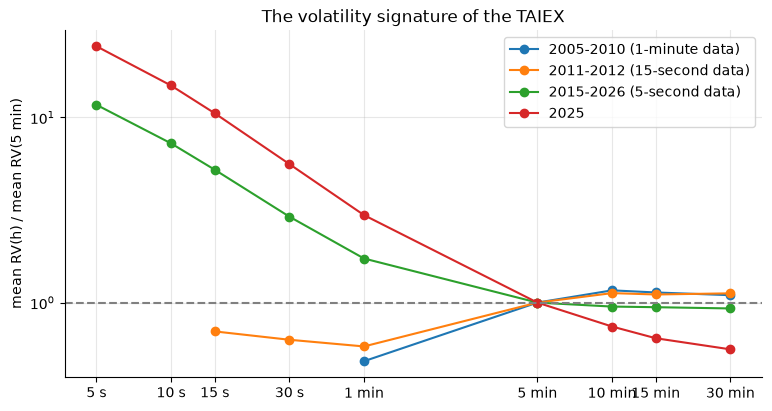

In [16]:
d_arr = np.array(rv_dates)
periods = {
    "2005-2010 (1-minute data)": (d_arr >= "2005-01-01") & (d_arr <= "2010-12-31"),
    "2011-2012 (15-second data)": (d_arr >= "2011-01-17") & (d_arr <= "2012-12-31"),
    "2015-2026 (5-second data)": d_arr >= "2015-01-01",
    "2025": ryear == "2025",
}
sig = {}
for name, msk in periods.items():
    m5 = float(np.mean(RV["5m"][msk]))
    sig[name] = [None if np.isnan(RV[k][msk]).any() else float(np.mean(RV[k][msk])) / m5 for k, _ in IV]
    print(f"{name}: {int(msk.sum())} days")
print(pl.DataFrame({"interval": [k for k, _ in IV], **{n: v for n, v in sig.items()}}))
show("2015-2026 at 5 s", sig["2015-2026 (5-second data)"][0], ".2f", "11.71")
show("2015-2026 at 30 min", sig["2015-2026 (5-second data)"][-1], ".3f", "0.930")
show("2025 at 5 s", sig["2025"][0], ".1f", "24.3")
show("2005-2010 at 1 min", sig["2005-2010 (1-minute data)"][4], ".3f", "0.483")

for name, vals in sig.items():
    xs = [h for (k, h), v in zip(IV, vals) if v is not None]
    plt.plot(xs, [v for v in vals if v is not None], marker="o", label=name)
plt.xscale("log")
plt.yscale("log")
plt.axhline(1, ls="--", color="grey")
plt.xticks([h for _, h in IV], ["5 s", "10 s", "15 s", "30 s", "1 min", "5 min", "10 min", "15 min", "30 min"])
plt.minorticks_off()
plt.ylabel("mean RV(h) / mean RV(5 min)")
plt.title("The volatility signature of the TAIEX")
plt.legend()
plt.show()

shape: (22, 3)
┌──────┬───────────────┬────────────────────┐
│ year ┆ RV(1m)/RV(5m) ┆ RV(10m)/RV(5m) - 1 │
│ ---  ┆ ---           ┆ ---                │
│ str  ┆ f64           ┆ f64                │
╞══════╪═══════════════╪════════════════════╡
│ 2005 ┆ 0.902         ┆ 0.238              │
│ 2006 ┆ 0.509         ┆ 0.246              │
│ 2007 ┆ 0.45          ┆ 0.256              │
│ 2008 ┆ 0.397         ┆ 0.158              │
│ 2009 ┆ 0.453         ┆ 0.071              │
│ 2010 ┆ 0.592         ┆ 0.174              │
│ 2011 ┆ 0.553         ┆ 0.139              │
│ 2012 ┆ 0.634         ┆ 0.109              │
│ 2013 ┆ 1.692         ┆ -0.011             │
│ 2014 ┆ 1.824         ┆ -0.007             │
│ 2015 ┆ 1.203         ┆ 0.111              │
│ 2016 ┆ 1.545         ┆ 0.039              │
│ 2017 ┆ 2.238         ┆ -0.06              │
│ 2018 ┆ 1.445         ┆ 0.037              │
│ 2019 ┆ 1.875         ┆ -0.03              │
│ 2020 ┆ 0.921         ┆ 0.084              │
│ 2021 ┆ 1.042     

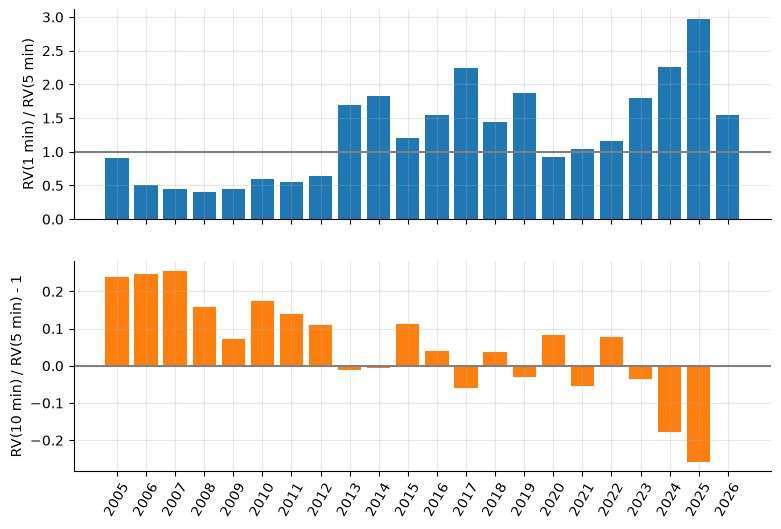

In [17]:
yrs = sorted(set(ryear))
top = {yy: float(np.mean(RV["1m"][ryear == yy]) / np.mean(RV["5m"][ryear == yy])) for yy in yrs}
bot = {yy: float(np.mean(RV["10m"][ryear == yy]) / np.mean(RV["5m"][ryear == yy]) - 1) for yy in yrs}
print(pl.DataFrame({"year": yrs, "RV(1m)/RV(5m)": [round(top[yy], 3) for yy in yrs],
                    "RV(10m)/RV(5m) - 1": [round(bot[yy], 3) for yy in yrs]}))
show("top, 2008 (lowest)", top["2008"], ".3f", "0.397")
show("top, 2025 (highest)", top["2025"], ".3f", "2.968")
print("top below 1:", [yy for yy in yrs if top[yy] < 1])
show("bottom, 2007 (highest)", bot["2007"], ".3f", "0.256")
show("bottom, 2025 (lowest)", bot["2025"], ".3f", "-0.257")
show("bottom, 2024", bot["2024"], ".3f", "-0.177")
print("bottom below -0.1:", [yy for yy in yrs if bot[yy] < -0.1 - EPS])

fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax[0].bar(yrs, [top[yy] for yy in yrs])
ax[0].axhline(1, color="grey")
ax[0].set_ylabel("RV(1 min) / RV(5 min)")
ax[1].bar(yrs, [bot[yy] for yy in yrs], color="C1")
ax[1].axhline(0, color="grey")
ax[1].set_ylabel("RV(10 min) / RV(5 min) - 1")
ax[1].tick_params(axis="x", rotation=60)
plt.show()

Example 8 from the file: by (26.6) with $J=2$, $\mathrm{RV}(2h)/\mathrm{RV}(h)-1$ estimates $\rho_1$ of the returns over $h$, a ratio of the period's means.

Deep Dive 3: under (26.7) the mean RV would rise by the same amount for every extra return a day. Each rise is the mean of a per-day series, so it gets a Newey–West standard error across the 5-second days. These errors need a finite fourth moment of returns (LM19), so they are nominal; the share of days on which the largest rise exceeds the smallest needs no moment.

In [18]:
m5s, m15 = reg == 5, reg == 15
show("5-second days: RV(10 s)/RV(5 s) - 1", float(np.mean(RV["10s"][m5s]) / np.mean(RV["5s"][m5s]) - 1), ".3f", "-0.381")
show("15-second days: RV(30 s)/RV(15 s)", float(np.mean(RV["30s"][m15]) / np.mean(RV["15s"][m15])), ".4f", "0.7189")
show("15-second days: RV(30 s)/RV(15 s) - 1", float(np.mean(RV["30s"][m15]) / np.mean(RV["15s"][m15]) - 1), ".3f", "-0.281")
show("all days: RV(10 min)/RV(5 min) - 1", float(np.mean(RV["10m"]) / np.mean(RV["5m"]) - 1), ".3f", "0.056")

ns = [14400 // h for _, h in IV[:6]]
mv = [float(np.mean(RV[k][m5s]) / np.mean(RV["5m"][m5s])) for k, _ in IV[:6]]
rise_per = [(mv[j] - mv[j + 1]) / (ns[j] - ns[j + 1]) for j in range(5)]
print("rise of mean RV(h)/RV(5 min) per extra return a day:", ", ".join(f"{v:.2e}" for v in rise_per))
show("smallest (x 1e-3)", 1e3 * min(rise_per), ".1f", "3.1")
show("largest (x 1e-3)", 1e3 * max(rise_per), ".1f", "4.9")

m5_mean = float(np.mean(RV["5m"][m5s]))
per_day = [(RV[IV[j][0]][m5s] - RV[IV[j + 1][0]][m5s]) / (ns[j] - ns[j + 1]) / m5_mean for j in range(5)]
nl5 = nw_lags(int(m5s.sum()))
print(f"{int(m5s.sum()):,} five-second days, {nl5} Newey-West lags")
for j, d_ in enumerate(per_day):
    se_j = nw_se(d_, nl5)
    print(f"{IV[j][0]}-{IV[j + 1][0]}: rise {d_.mean():.3e}, SE {se_j:.1e}, SE / rise {se_j / d_.mean():.3f}")
jx, jn = int(np.argmax(rise_per)), int(np.argmin(rise_per))
d_x = per_day[jx] - per_day[jn]
print(f"largest minus smallest: {d_x.mean():.3e}, t-stat {d_x.mean() / nw_se(d_x, nl5):.2f}")
show("the extremes' per-day correlation", float(np.corrcoef(per_day[jx], per_day[jn])[0, 1]), ".2f", "0.93")
show("Newey-West t-stat of their per-day difference", float(d_x.mean() / nw_se(d_x, nl5)), ".1f", "10.6")
show("days on which the largest rise exceeds the smallest (%)", 100 * float(np.mean(d_x > 0)), ".0f", "88")

5-second days: RV(10 s)/RV(5 s) - 1: -0.381   [book: -0.381]
15-second days: RV(30 s)/RV(15 s): 0.7189   [book: 0.7189]
15-second days: RV(30 s)/RV(15 s) - 1: -0.281   [book: -0.281]
all days: RV(10 min)/RV(5 min) - 1: 0.056   [book: 0.056]
rise of mean RV(h)/RV(5 min) per extra return a day: 3.10e-03, 4.22e-03, 4.81e-03, 4.93e-03, 3.81e-03
smallest (x 1e-3): 3.1   [book: 3.1]
largest (x 1e-3): 4.9   [book: 4.9]
2,870 five-second days, 8 Newey-West lags
5s-10s: rise 3.102e-03, SE 2.7e-04, SE / rise 0.088
10s-15s: rise 4.221e-03, SE 3.7e-04, SE / rise 0.087
15s-30s: rise 4.812e-03, SE 4.1e-04, SE / rise 0.085
30s-1m: rise 4.929e-03, SE 4.3e-04, SE / rise 0.088
1m-5m: rise 3.805e-03, SE 4.4e-04, SE / rise 0.115
largest minus smallest: 1.827e-03, t-stat 10.59
the extremes' per-day correlation: 0.93   [book: 0.93]
Newey-West t-stat of their per-day difference: 10.6   [book: 10.6]
days on which the largest rise exceeds the smallest (%): 88   [book: 88]


In [19]:
o2_share = float(np.mean(1e4 * O2) / np.mean(Vt["15m"]))
show("opening return's share of mean V_t, all days (%)", 100 * o2_share, ".0f", "66")
mo = np.isin(d_arr, [dates[i] for i in oos])
show("on the out-of-sample days (%)", 100 * float(np.mean(1e4 * O2[mo]) / np.mean(Vt["15m"][mo])), ".0f", "68")
print(f"(all days: {len(O2):,}; out-of-sample days: {int(mo.sum()):,})")

y2 = y[i05:] ** 2
dV = Vt["15m"] - y2
show("mean V_t / mean r_t^2", float(np.mean(Vt["15m"]) / np.mean(y2)), ".3f", "0.933")
show("Newey-West lags for 5,351 days", nw_lags(len(dV)), "d", "9")
show("t-stat of the difference", float(dV.mean() / nw_se(dV, nw_lags(len(dV)))), ".2f", "-3.26")
for yy, v_ in (("2025", "0.918"), ("2008", "1.011")):
    show(f"ratio in {yy}", float(np.mean(Vt["15m"][ryear == yy]) / np.mean(y2[ryear == yy])), ".3f", v_)

opening return's share of mean V_t, all days (%): 66   [book: 66]
on the out-of-sample days (%): 68   [book: 68]
(all days: 5,351; out-of-sample days: 4,609)
mean V_t / mean r_t^2: 0.933   [book: 0.933]
Newey-West lags for 5,351 days: 9   [book: 9]
t-stat of the difference: -3.26   [book: -3.26]
ratio in 2025: 0.918   [book: 0.918]
ratio in 2008: 1.011   [book: 1.011]


## Part 7 — Judging forecasts out of sample (Exhibit 7, Example 10)

Both GARCH models are refitted at each month's first session on the previous 1,231 returns. The recursion restarts at the window's first day from that window's backcast and runs with the new parameters through the month. The forecast of day $t$ is made at the close of day $t-1$. This cell runs 452 fits (several seconds).

In [20]:
def rolling_garch(window):
    out = {"normal": np.full(T, np.nan), "t": np.full(T, np.nan)}
    f0 = next(i for i in starts if i >= window)
    n_fit = 0
    for k, s in enumerate(starts):
        if s < f0:
            continue
        e_end = starts[k + 1] if k + 1 < len(starts) else T
        win = y[s - window : s]
        bcw = backcast(win - win.mean())
        for dist in ("normal", "t"):
            res = fit(win, dist)
            p = res.params.to_numpy()
            path = garch_filter(p[1], p[2], p[3], y[s - window : e_end] - p[0], bcw)
            if s == f0:                                   # the hand recursion is arch's on the window
                assert np.max(np.abs(path[:window] - np.asarray(res.conditional_volatility) ** 2)) < 1e-9
            out[dist][s:e_end] = path[window : window + (e_end - s)]
            n_fit += dist == "normal"
    return out, n_fit


t0 = time.perf_counter()
rg, n_refit = rolling_garch(W)
print(f"rolling refits in {time.perf_counter() - t0:.0f} s")
show("refits per model", n_refit, "d", "226")

FC = {"roll60": np.full(T, np.nan), "ewma": np.full(T, np.nan), "garch_n": rg["normal"], "garch_t": rg["t"],
      "v_prev": np.full(T, np.nan), "ewma_v": np.full(T, np.nan)}
NAMES = {"roll60": "Rolling 60-day", "ewma": "EWMA 0.94", "garch_n": "GARCH normal", "garch_t": "GARCH t",
         "v_prev": "Yesterday's V", "ewma_v": "EWMA of V"}
ewv = np.full(T + 1, np.nan)
ewv[i05] = V15[i05]
for t in range(i05, T):
    ewv[t + 1] = LAM * ewv[t] + (1 - LAM) * V15[t]
c2 = np.concatenate([[0.0], np.cumsum(y**2)])
FC["ewma"][oos] = ew[oos]
FC["roll60"][oos] = (c2[oos] - c2[oos - 60]) / 60
FC["v_prev"][oos] = V15[oos - 1]
FC["ewma_v"][oos] = ewv[oos]
assert not any(np.isnan(FC[k][oos]).any() for k in FC)

rolling refits in 6 s
refits per model: 226   [book: 226]


Exhibit 1: the forecasts for 7 and 8 April 2025, as daily standard deviations.

In [21]:
for lab, i, vals in (("2 April -> 7 April", i7, ["1.7222", "1.5605", "1.3226", "0.7004"]),
                     ("7 April -> 8 April", i8, ["3.6031", "2.9215", "1.8665", "10.0859"])):
    got = [f"{math.sqrt(FC[k][i]):.4f}" for k in ("garch_n", "ewma", "roll60", "v_prev")]
    print(f"{lab}: GARCH {got[0]}, EWMA {got[1]}, 60-day {got[2]}, yesterday's V {got[3]}; realized "
          f"{math.sqrt(V15[i]):.4f}; r {y[i]:.4f}")
    assert got == vals, (got, vals)
show("GARCH for 7 April, a year", ann(FC["garch_n"][i7]), ".1f", "27.0")
show("7 April's log return in GARCH standard deviations", -y[i7] / math.sqrt(FC["garch_n"][i7]), ".1f", "5.9")
pre, post = np.arange(i7 - 20, i7), np.arange(i7, i7 + 20)
show("realized, the 20 sessions before 7 April (% a year)", ann(float(V15[pre].mean())), ".1f", "19.8")
show("realized, the 20 sessions from 7 April", ann(float(V15[post].mean())), ".1f", "54.3")
show("GARCH's mean forecast over them", ann(float(FC["garch_n"][post].mean())), ".1f", "48.9")
show("EWMA's mean forecast over them", ann(float(FC["ewma"][post].mean())), ".1f", "50.1")

2 April -> 7 April: GARCH 1.7222, EWMA 1.5605, 60-day 1.3226, yesterday's V 0.7004; realized 10.0859; r -10.2029
7 April -> 8 April: GARCH 3.6031, EWMA 2.9215, 60-day 1.8665, yesterday's V 10.0859; realized 3.3873; r -4.0990
GARCH for 7 April, a year: 27.0   [book: 27.0]
7 April's log return in GARCH standard deviations: 5.9   [book: 5.9]
realized, the 20 sessions before 7 April (% a year): 19.8   [book: 19.8]
realized, the 20 sessions from 7 April: 54.3   [book: 54.3]
GARCH's mean forecast over them: 48.9   [book: 48.9]
EWMA's mean forecast over them: 50.1   [book: 50.1]


Exhibit 7: mean forecast, MSE (%⁴), QLIKE, the Mincer–Zarnowitz slope with HC0 errors, R-squared, and the Newey–West t-stat of the daily QLIKE difference from GARCH normal (9 lags). Both kinds of error are checked against statsmodels, the second against its HAC with `use_correction` off, its default.

In [22]:
def ols_hc0(X, v):
    b, *_ = np.linalg.lstsq(X, v, rcond=None)
    e = v - X @ b
    xtxi = np.linalg.inv(X.T @ X)
    se = np.sqrt(np.diag(xtxi @ ((X * e[:, None] ** 2).T @ X) @ xtxi))
    return b, se, 1 - float(e @ e) / float((v - v.mean()) @ (v - v.mean()))


hV = V15[oos]
nl = nw_lags(len(oos))
show("Newey-West lags for 4,609 days", nl, "d", "9")
show("target mean (%^2)", float(hV.mean()), ".3f", "1.368")
rows, LD = [], {}
for k in FC:
    f = FC[k][oos]
    X = np.column_stack([np.ones(len(f)), f])
    b, se, r2 = ols_hc0(X, hV)
    assert np.allclose(sm.OLS(hV, X).fit(cov_type="HC0").bse, se, rtol=1e-9)
    for lname, loss in (("MSE", lambda f_: (hV - f_) ** 2), ("QLIKE", lambda f_: qlike(hV, f_))):
        d = loss(f) - loss(FC["garch_n"][oos])
        if k != "garch_n":
            se_d = nw_se(d, nl)
            if (k, lname) == ("ewma", "QLIKE"):
                hac = sm.OLS(d, np.ones(len(d))).fit(cov_type="HAC", cov_kwds={"maxlags": nl})
                assert abs(float(hac.bse[0]) - se_d) < 1e-10 * se_d
            LD[(k, lname)] = (float(d.mean()), float(d.mean() / se_d))
    rows.append({"forecast": NAMES[k], "mean": f"{f.mean():.3f}", "MSE": f"{((hV - f) ** 2).mean():.2f}",
                 "QLIKE": f"{qlike(hV, f).mean():.4f}", "b (HC0 SE)": f"{b[1]:.3f} ({se[1]:.3f})",
                 "R-squared": f"{r2:.3f}", "t-stat, QLIKE": "-" if k == "garch_n" else f"{LD[(k, 'QLIKE')][1]:.2f}"})
x7 = pl.DataFrame(rows)
print(x7)
book7 = [["1.466", "11.48", "0.5774", "0.763 (0.059)", "0.093", "4.82"],
         ["1.464", "10.80", "0.5153", "0.850 (0.083)", "0.143", "1.83"],
         ["1.411", "10.37", "0.5032", "0.980 (0.114)", "0.172", "-"],
         ["1.394", "10.41", "0.5077", "1.010 (0.118)", "0.168", "1.40"],
         ["1.368", "18.18", "1.1778", "0.274 (0.054)", "0.075", "11.96"],
         ["1.370", "10.78", "0.5209", "0.864 (0.074)", "0.143", "1.46"]]
assert [list(row.values())[1:] for row in rows] == book7
print("the table agrees with the module")

Newey-West lags for 4,609 days: 9   [book: 9]
target mean (%^2): 1.368   [book: 1.368]
shape: (6, 7)
┌────────────────┬───────┬───────┬────────┬───────────────┬───────────┬───────────────┐
│ forecast       ┆ mean  ┆ MSE   ┆ QLIKE  ┆ b (HC0 SE)    ┆ R-squared ┆ t-stat, QLIKE │
│ ---            ┆ ---   ┆ ---   ┆ ---    ┆ ---           ┆ ---       ┆ ---           │
│ str            ┆ str   ┆ str   ┆ str    ┆ str           ┆ str       ┆ str           │
╞════════════════╪═══════╪═══════╪════════╪═══════════════╪═══════════╪═══════════════╡
│ Rolling 60-day ┆ 1.466 ┆ 11.48 ┆ 0.5774 ┆ 0.763 (0.059) ┆ 0.093     ┆ 4.82          │
│ EWMA 0.94      ┆ 1.464 ┆ 10.80 ┆ 0.5153 ┆ 0.850 (0.083) ┆ 0.143     ┆ 1.83          │
│ GARCH normal   ┆ 1.411 ┆ 10.37 ┆ 0.5032 ┆ 0.980 (0.114) ┆ 0.172     ┆ -             │
│ GARCH t        ┆ 1.394 ┆ 10.41 ┆ 0.5077 ┆ 1.010 (0.118) ┆ 0.168     ┆ 1.40          │
│ Yesterday's V  ┆ 1.368 ┆ 18.18 ┆ 1.1778 ┆ 0.274 (0.054) ┆ 0.075     ┆ 11.96         │
│ EWMA of V      ┆ 

In [23]:
d_q, t_q = LD[("ewma", "QLIKE")]
show("EWMA minus GARCH normal, QLIKE", d_q, ".4f", "0.0121")
show("its t-stat", t_q, ".2f", "1.83")
show("its two-sided p-value", float(2 * stats.norm.sf(abs(t_q))), ".3f", "0.067")
show("EWMA minus GARCH normal, MSE (%^4)", LD[("ewma", "MSE")][0], ".3f", "0.428")
show("its t-stat", LD[("ewma", "MSE")][1], ".2f", "2.98")
show("GARCH t, QLIKE t-stat", LD[("garch_t", "QLIKE")][1], ".2f", "1.40")
show("GARCH t, MSE t-stat", LD[("garch_t", "MSE")][1], ".2f", "0.62")
show("yesterday's V, QLIKE t-stat", LD[("v_prev", "QLIKE")][1], ".2f", "11.96")

X = np.column_stack([np.ones(len(oos)), FC["garch_n"][oos]])
b, se, r2 = ols_hc0(X, hV)
show("Mincer-Zarnowitz a", b[0], ".3f", "-0.015")
show("its HC0 SE", se[0], ".3f", "0.135")
show("Mincer-Zarnowitz b", b[1], ".3f", "0.980")
show("its HC0 SE", se[1], ".3f", "0.114")
show("t-stat for b = 1", (b[1] - 1) / se[1], ".2f", "-0.18")
show("R-squared", r2, ".3f", "0.172")
show("R-squared against r_t^2", ols_hc0(X, y[oos] ** 2)[2], ".3f", "0.119")

targets = {"V(15 min)": hV, "V(5 min)": 1e4 * (O2 + RV["5m"])[mo], "V(30 min)": 1e4 * (O2 + RV["30m"])[mo],
           "r^2": y[oos] ** 2}
for tg, h in targets.items():
    order = sorted(FC, key=lambda k: float(qlike(h, FC[k][oos]).mean()))
    print(f"QLIKE order against {tg}: " + ", ".join(NAMES[k] for k in order))

EWMA minus GARCH normal, QLIKE: 0.0121   [book: 0.0121]
its t-stat: 1.83   [book: 1.83]
its two-sided p-value: 0.067   [book: 0.067]
EWMA minus GARCH normal, MSE (%^4): 0.428   [book: 0.428]
its t-stat: 2.98   [book: 2.98]
GARCH t, QLIKE t-stat: 1.40   [book: 1.40]
GARCH t, MSE t-stat: 0.62   [book: 0.62]
yesterday's V, QLIKE t-stat: 11.96   [book: 11.96]
Mincer-Zarnowitz a: -0.015   [book: -0.015]
its HC0 SE: 0.135   [book: 0.135]
Mincer-Zarnowitz b: 0.980   [book: 0.980]
its HC0 SE: 0.114   [book: 0.114]
t-stat for b = 1: -0.18   [book: -0.18]
R-squared: 0.172   [book: 0.172]
R-squared against r_t^2: 0.119   [book: 0.119]
QLIKE order against V(15 min): GARCH normal, GARCH t, EWMA 0.94, EWMA of V, Rolling 60-day, Yesterday's V
QLIKE order against V(5 min): GARCH normal, GARCH t, EWMA 0.94, EWMA of V, Rolling 60-day, Yesterday's V
QLIKE order against V(30 min): GARCH normal, GARCH t, EWMA 0.94, EWMA of V, Rolling 60-day, Yesterday's V
QLIKE order against r^2: GARCH normal, GARCH t, EWM

Exhibit 8 and Exhibit 9: QLIKE by calendar year, and 2025 by ISO week (each point a week's mean of $V_t$ or of a forecast, annualized).

shape: (19, 4)
┌──────┬──────────────┬───────────┬───────────────┐
│ year ┆ GARCH normal ┆ EWMA 0.94 ┆ yesterday's V │
│ ---  ┆ ---          ┆ ---       ┆ ---           │
│ str  ┆ f64          ┆ f64       ┆ f64           │
╞══════╪══════════════╪═══════════╪═══════════════╡
│ 2008 ┆ 0.415        ┆ 0.426     ┆ 0.905         │
│ 2009 ┆ 0.352        ┆ 0.354     ┆ 0.822         │
│ 2010 ┆ 0.433        ┆ 0.424     ┆ 1.304         │
│ 2011 ┆ 0.502        ┆ 0.522     ┆ 1.14          │
│ 2012 ┆ 0.486        ┆ 0.468     ┆ 0.994         │
│ 2013 ┆ 0.466        ┆ 0.421     ┆ 1.002         │
│ 2014 ┆ 0.471        ┆ 0.472     ┆ 0.979         │
│ 2015 ┆ 0.464        ┆ 0.464     ┆ 1.105         │
│ 2016 ┆ 0.461        ┆ 0.469     ┆ 1.147         │
│ 2017 ┆ 0.398        ┆ 0.342     ┆ 0.767         │
│ 2018 ┆ 0.652        ┆ 0.693     ┆ 1.317         │
│ 2019 ┆ 0.544        ┆ 0.543     ┆ 1.285         │
│ 2020 ┆ 0.666        ┆ 0.785     ┆ 1.263         │
│ 2021 ┆ 0.372        ┆ 0.435     ┆ 0.713        

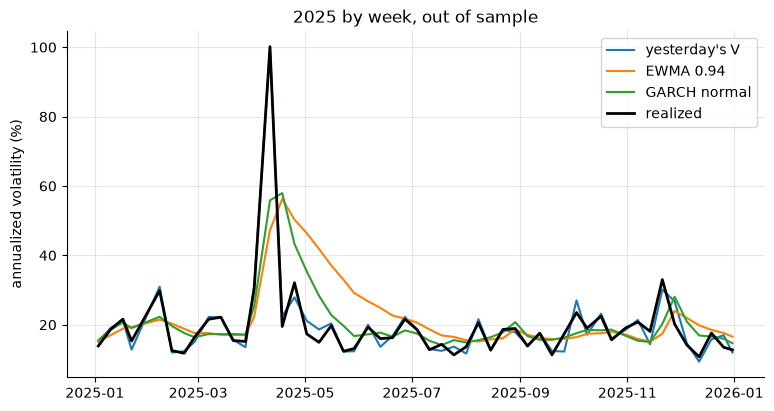

In [24]:
oy = np.array([dates[i][:4] for i in oos])
by = {yy: [float(qlike(hV[oy == yy], FC[k][oos][oy == yy]).mean()) for k in ("garch_n", "ewma", "v_prev")]
      for yy in sorted(set(oy))}
print(pl.DataFrame({"year": list(by), "GARCH normal": [round(v[0], 3) for v in by.values()],
                    "EWMA 0.94": [round(v[1], 3) for v in by.values()],
                    "yesterday's V": [round(v[2], 3) for v in by.values()]}))
show("years with GARCH below EWMA", sum(v[0] < v[1] for v in by.values()), "d", "12")
show("years", len(by), "d", "19")
show("2025: GARCH", by["2025"][0], ".3f", "0.611")
show("2025: EWMA", by["2025"][1], ".3f", "0.733")
show("2020: GARCH", by["2020"][0], ".3f", "0.666")
show("2020: EWMA", by["2020"][1], ".3f", "0.785")
show("2026 days (to 8 October)", int((oy == "2026").sum()), "d", "185")

w25 = {}
for i in oos:
    if dates[i].startswith("2025"):
        w25.setdefault(dt.date.fromisoformat(dates[i]).isocalendar()[:2], []).append(i)
wk = list(w25.values())
show("2025 weeks", len(wk), "d", "52")
ids7 = next(ids for ids in wk if i7 in ids)
show("week of 7 April: realized", ann(float(V15[ids7].mean())), ".2f", "100.16")
show("GARCH normal", ann(float(FC["garch_n"][ids7].mean())), ".2f", "55.86")
show("EWMA", ann(float(FC["ewma"][ids7].mean())), ".2f", "47.22")
show("yesterday's V", ann(float(FC["v_prev"][ids7].mean())), ".2f", "99.52")
show("2025's realized volatility", ann(float(V15[[i for ids in wk for i in ids]].mean())), ".2f", "23.33")
xw = [dt.date.fromisoformat(dates[ids[-1]]) for ids in wk]
for k, lab in (("v_prev", "yesterday's V"), ("ewma", "EWMA 0.94"), ("garch_n", "GARCH normal")):
    plt.plot(xw, [ann(float(FC[k][ids].mean())) for ids in wk], label=lab)
plt.plot(xw, [ann(float(V15[ids].mean())) for ids in wk], color="black", lw=2, label="realized")
plt.ylabel("annualized volatility (%)")
plt.title("2025 by week, out of sample")
plt.legend()
plt.show()

The window check (a stability check): the same design with windows of 1,000 and 2,461 returns. This cell runs about 800 more fits.

In [25]:
t0 = time.perf_counter()
for wv, vals, day0 in ((1000, ("0.5029", "0.5126"), "2007-02-01"), (2461, ("0.5332", "0.5421"), "2012-12-03")):
    rg2, _ = rolling_garch(wv)
    f0 = next(i for i in starts if i >= wv)
    assert dates[f0] == day0                       # the module: forecasts from 1 February 2007 and 3 December 2012
    o2_ = np.arange(f0, T)
    qn = float(qlike(V15[o2_], rg2["normal"][o2_]).mean())
    qt = float(qlike(V15[o2_], rg2["t"][o2_]).mean())
    qe = float(qlike(V15[o2_], ew[o2_]).mean())
    print(f"window {wv}: first day {dates[f0]}, {len(o2_)} days; QLIKE GARCH normal {qn:.4f}, GARCH t {qt:.4f}, "
          f"EWMA {qe:.4f}")
    show(f"window {wv}: GARCH normal", qn, ".4f", vals[0])
    show(f"window {wv}: EWMA", qe, ".4f", vals[1])
    assert qn < min(qt, qe)
print(f"{time.perf_counter() - t0:.0f} s")

window 1000: first day 2007-02-01, 4834 days; QLIKE GARCH normal 0.5029, GARCH t 0.5070, EWMA 0.5126
window 1000: GARCH normal: 0.5029   [book: 0.5029]
window 1000: EWMA: 0.5126   [book: 0.5126]
window 2461: first day 2012-12-03, 3382 days; QLIKE GARCH normal 0.5332, GARCH t 0.5392, EWMA 0.5421
window 2461: GARCH normal: 0.5332   [book: 0.5332]
window 2461: EWMA: 0.5421   [book: 0.5421]
12 s


## Part 8 — Practice problems 10, 11 and 12

**Problem 10.** The normal GARCH log-likelihood (26.5) by hand, from arch's backcast (about the sample mean, 2.78 %²), at arch's estimates (Part 4 did it): $\ell$ and $\hat\sigma_t$ on 7 April 2025. A backcast about $\hat g$ instead gives a slightly different $\ell$.

In [26]:
show("P10: l by hand", ll, ",.2f", "-8,647.25")
show("P10: sigma_t on 7 April 2025 (%)", math.sqrt(s2[i7]), ".3f", "1.737")
s2_g = garch_filter(pn[1], pn[2], pn[3], y - pn[0], backcast(y - pn[0]))
ll_g = -0.5 * float(np.sum(np.log(2 * np.pi) + np.log(s2_g[:T]) + (y - pn[0]) ** 2 / s2_g[:T]))
print(f"backcast about g: {backcast(y - pn[0]):.4f} %^2, l {ll_g:.4f}; about the sample mean: {bc:.4f} %^2, l {ll:.4f}")

P10: l by hand: -8,647.25   [book: -8,647.25]
P10: sigma_t on 7 April 2025 (%): 1.737   [book: 1.737]
backcast about g: 2.7677 %^2, l -8647.2551; about the sample mean: 2.7800 %^2, l -8647.2521


**Problem 11.** Section 7's EWMA (0.94) and GARCH-normal forecasts (Part 7 built them): mean QLIKE against $V_t$ and the Newey–West t-stat of the difference with 9 lags.

In [27]:
q_e, q_g = float(qlike(hV, FC["ewma"][oos]).mean()), float(qlike(hV, FC["garch_n"][oos]).mean())
show("P11: EWMA", q_e, ".4f", "0.5153")
show("P11: GARCH normal", q_g, ".4f", "0.5032")
d = qlike(hV, FC["ewma"][oos]) - qlike(hV, FC["garch_n"][oos])
show("P11: t-stat", float(d.mean() / nw_se(d, 9)), ".2f", "1.83")

P11: EWMA: 0.5153   [book: 0.5153]
P11: GARCH normal: 0.5032   [book: 0.5032]
P11: t-stat: 1.83   [book: 1.83]


**Problem 12.** The 2015–2026 line of Exhibit 4 from `vol4_rv.csv`. Then $\hat\rho_1$ of 5-second returns on the 5-second days, by the ratio of the period's mean $\mathrm{RV}(10\text{ s})$ to its mean $\mathrm{RV}(5\text{ s})$, minus 1. A mean of daily ratios gives another number.

In [28]:
msk = d_arr >= "2015-01-01"
line = [float(np.mean(RV[k][msk]) / np.mean(RV["5m"][msk])) for k, _ in IV]
print(", ".join(f"{k} {v:.3f}" for (k, _), v in zip(IV, line)))
show("P12: 5 s", line[0], ".2f", "11.71")
show("P12: 30 min", line[-1], ".3f", "0.930")
show("P12: rho_1 estimate", float(np.mean(RV["10s"][m5s]) / np.mean(RV["5s"][m5s]) - 1), ".3f", "-0.381")
print(f"the mean of daily ratios, for contrast: {float(np.mean(RV['10s'][m5s] / RV['5s'][m5s])) - 1:.3f}")

5s 11.713, 10s 7.248, 15s 5.222, 30s 2.913, 1m 1.730, 5m 1.000, 10m 0.952, 15m 0.944, 30m 0.930
P12: 5 s: 11.71   [book: 11.71]
P12: 30 min: 0.930   [book: 0.930]
P12: rho_1 estimate: -0.381   [book: -0.381]
the mean of daily ratios, for contrast: -0.358


## Part 9 — Optional: the 2025 numbers "from the raw download"

The module prints a few 2025 statistics that the per-day file cannot give: each day's $\hat\rho_1$ of 5-second returns, the pooled 2025 value and the pooled 1-minute value. They need the 243 files of 2025 from the 5-second download (243 requests): from the repository root run `uv run python data/fetch_intraday.py --series taiex5s --from 2025-01-01 --to 2025-12-31`, then copy `data/raw/intraday/taiex5s/2025/` to this lab's `data/taiex5s_2025/`. FinMind's licence does not allow the book to redistribute them. The pooled values over all years need the whole download (`data/lm26_numbers.py`).

Returns on the grid 09:30:00, 09:30:05, …, 13:30:00; pooled autocorrelations use within-day pairs only, uncentred; each day's own value is centred at that day's mean.

In [29]:
RAW25 = DATA / "taiex5s_2025"
files = sorted(RAW25.glob("*.csv")) if RAW25.is_dir() else []
if len(files) != 243:
    print(f"skipped: {len(files)} of the 243 files of 2025 in {RAW25.as_posix()}/ (the module prints: pooled 5-second rho_1 "
          "-0.386, each day's from -0.52 to -0.19 with the middle half from -0.41 to -0.33, pooled 1-minute rho_1 -0.421, "
          "RV(5 s)/RV(5 min) 25.2 on the median day and up to 62.6)")
else:
    START, CLOSE = 9 * 3600 + 30 * 60, 13 * 3600 + 30 * 60
    p1 = {"5s": 0.0, "1m": 0.0}
    ss = {"5s": 0.0, "1m": 0.0}
    rho_day, ratio_day = [], []
    for f in files:
        x = pl.read_csv(f, schema_overrides={"date": pl.String, "TAIEX": pl.Float64})
        tt = x["date"].str.slice(11, 8).to_list()
        at = {int(a[:2]) * 3600 + int(a[3:5]) * 60 + int(a[6:8]): j for j, a in enumerate(tt)}
        lv = np.log(x["TAIEX"].to_numpy())
        for key, h in (("5s", 5), ("1m", 60)):
            rr = np.diff(lv[[at[s] for s in range(START, CLOSE + 1, h)]])
            p1[key] += float(rr[1:] @ rr[:-1])
            ss[key] += float(rr @ rr)
            if key == "5s":
                rc = rr - rr.mean()
                rho_day.append(float(rc[1:] @ rc[:-1]) / float(rc @ rc))
                r5m = np.diff(lv[[at[s] for s in range(START, CLOSE + 1, 300)]])
                ratio_day.append(float(rr @ rr) / float(r5m @ r5m))
    rho_day, ratio_day = np.array(rho_day), np.array(ratio_day)
    show("pooled 5-second rho_1, 2025", p1["5s"] / ss["5s"], ".3f", "-0.386")
    show("noise share 2|rho_1| (%)", 200 * abs(p1["5s"] / ss["5s"]), ".0f", "77")
    show("each day's rho_1: lowest", rho_day.min(), ".2f", "-0.52")
    show("highest", rho_day.max(), ".2f", "-0.19")
    show("25%", qinv(rho_day, 0.25), ".2f", "-0.41")
    show("75%", qinv(rho_day, 0.75), ".2f", "-0.33")
    show("pooled 1-minute rho_1, 2025", p1["1m"] / ss["1m"], ".3f", "-0.421")
    show("RV(5 s)/RV(5 min), median day", qinv(ratio_day, 0.5), ".1f", "25.2")
    show("largest", ratio_day.max(), ".1f", "62.6")

skipped: 0 of the 243 files of 2025 in data/taiex5s_2025/ (the module prints: pooled 5-second rho_1 -0.386, each day's from -0.52 to -0.19 with the middle half from -0.41 to -0.33, pooled 1-minute rho_1 -0.421, RV(5 s)/RV(5 min) 25.2 on the median day and up to 62.6)


## Part 10 — Extension: an asymmetric GARCH

Example 7 found that the data raise the risk of a fall more after falls than after rises, which GARCH(1,1) cannot express. arch's `o=1` adds a term $\gamma\,\varepsilon_{t-1}^2\mathbf 1\{\varepsilon_{t-1}<0\}$ to (26.3) (the asymmetry Hansen and Lunde call a "leverage effect").

Fit it to TR23. With the new residuals' own distribution, recompute the expected number of falls after the 108 falls and after the 67 rises. Compare them with 13 and 3 observed and with GARCH(1,1)'s 7.8 and 5.4. Does the model now expect more falls after falls than after rises?

Then compare the log-likelihoods, and decide whether the gain is worth one parameter. The fit is in-sample; LM34 tests such choices on later data.

In [30]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    gjr = arch_model(y, mean="Constant", vol="GARCH", p=1, o=1, q=1).fit(disp="off")
pg = gjr.params.to_numpy()                     # g, omega, alpha, gamma, beta
print(gjr.params.round(4).to_dict(), f"log-likelihood {gjr.loglikelihood:,.2f} against {gn.loglikelihood:,.2f}")
cv_g = np.asarray(gjr.conditional_volatility)
xi_g = (y - pg[0]) / cv_g
sn_g = cv_g[1:]                                # sigma_{t+1}, known at the close of day t (t = 0 .. T-2)
F_g = np.searchsorted(np.sort(xi_g), (100 * math.log(0.97) - pg[0]) / sn_g, side="right") / T
print(f"expected falls after the {len(idf)} falls: {F_g[idf].sum():.1f}; after the {len(idr)} rises: {F_g[idr].sum():.1f}")
# your code: the same with the t distribution (dist="t"), and the out-of-sample QLIKE of a rolling GJR forecast

{'mu': 0.0612, 'omega': 0.0323, 'alpha[1]': 0.0362, 'gamma[1]': 0.1058, 'beta[1]': 0.8862} log-likelihood -8,600.34 against -8,647.25
expected falls after the 108 falls: 9.5; after the 67 rises: 4.8
